# Unit 17 — Predictive Analysis and Forecasting

A non-ML introduction to forecasting and business prediction using time-series data.

## Learning Objectives
- Distinguish descriptive, diagnostic, predictive and prescriptive analytics.
- Explain the components of time-series data.
- Build simple baseline forecasts.
- Compare forecasts using MAE.
- Interpret forecasts for business decisions.
- Explain forecasting limitations and uncertainty.

## Prerequisites
- Pandas time-series
- NumPy
- Matplotlib
- Basic statistics

## Class Delivery
Approx. 60 minutes. Keep the maths light and emphasise interpretation, baseline comparison and business use.

> **Teaching pattern:** explain the concept → demonstrate → interpret → practise → connect to a business decision.

## 1. From Historical Analysis to Prediction

Students already know how to answer:

> What happened?

Predictive analysis asks:

> What might happen next?

This does not require machine learning.

For this unit we will use **simple statistical and time-series forecasting techniques**. Machine learning models can be taught in the next unit.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (10, 5)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.3
Pandas: 3.0.5


## 2. Four Levels of Analytics

```text
Descriptive   → What happened?
Diagnostic    → Why did it happen?
Predictive    → What might happen?
Prescriptive  → What should we do?
```

### Example — Sales

- Descriptive: sales fell by 12%.
- Diagnostic: the fall was concentrated in one region.
- Predictive: sales may fall again next month.
- Prescriptive: management should review pricing/promotion/inventory decisions.

This is a useful framework for communicating business analysis.

## 3. What Is Predictive Analysis?

Predictive analysis uses historical data, patterns and statistical techniques to estimate future or unknown outcomes.

It may be used for:

- sales forecasting
- demand forecasting
- inventory planning
- staffing
- website traffic
- energy usage
- customer activity

A forecast is **an estimate, not a guarantee**.

## 4. What Is a Time Series?

A time series contains observations ordered through time.

Examples:

- daily sales
- monthly revenue
- hourly traffic
- weekly orders
- annual demand

Time order matters. We should not randomly shuffle a time series when evaluating a forecast.

## 5. Components of Time-Series Data

### Trend
Long-term upward/downward direction.

### Seasonality
Repeated pattern at a known interval.

### Cycles
Longer fluctuations that do not necessarily repeat at a fixed frequency.

### Noise
Random variation that is difficult to predict.

In [17]:
rng = np.random.default_rng(21)

dates = pd.date_range("2025-01-01", periods=36, freq="MS")
trend = np.linspace(100_000, 145_000, 36)
seasonal_pattern = np.tile([0.90, 0.95, 1.00, 1.03, 1.06, 1.10, 1.04, 1.00, 0.96, 0.98, 1.03, 1.15], 3)
noise = rng.normal(0, 2500, 36)

monthly_sales = pd.DataFrame({
    "date": dates,
    "sales": trend * seasonal_pattern + noise
})

monthly_sales.head()

,date,sales
0,2025-01-01,90896.933520
1,2025-02-01,99998.121842
2,2025-03-01,98105.600478
3,2025-04-01,111189.390915
4,2025-05-01,111333.135541


## 6. Visualise the Time Series

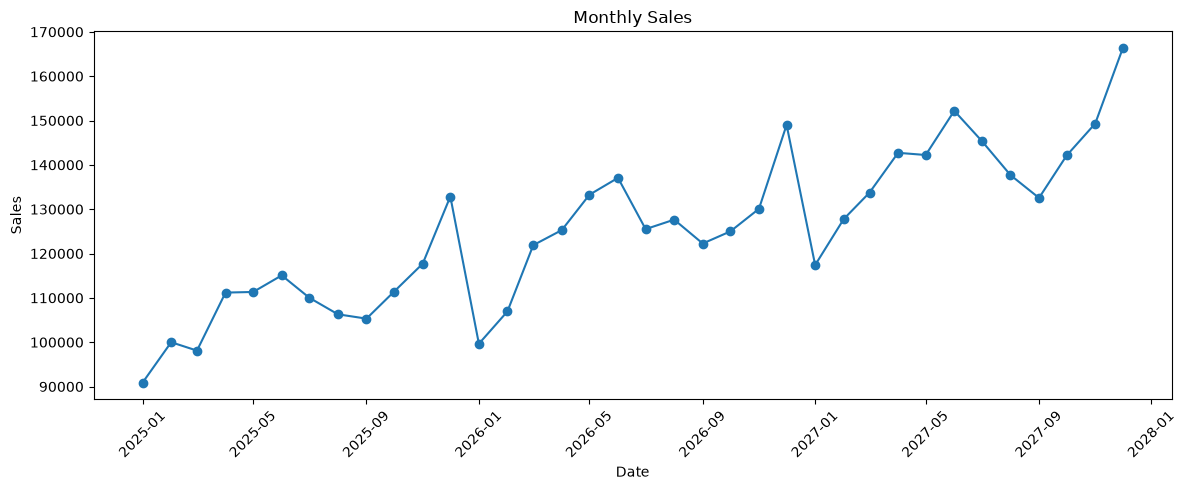

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["date"], monthly_sales["sales"], marker="o")
plt.title("Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Identify Trend and Seasonality

Ask students:

1. Is the overall direction increasing or decreasing?
2. Are there recurring high/low months?
3. Which months appear strongest?
4. Is the pattern stable?
5. What business process might cause the pattern?

This is where the notebook moves from graph reading to business interpretation.

In [19]:
monthly_sales["month"] = monthly_sales["date"].dt.month
seasonal_summary = monthly_sales.groupby("month")["sales"].mean()
seasonal_summary

month
1     102649.852881
2     111572.113347
3     117909.974067
4     126397.823038
5     128940.223482
6     134776.973651
7     126961.483365
8     123877.002594
9     120038.616669
10    126178.573840
11    132368.978115
12    149405.943741
Name: sales, dtype: float64

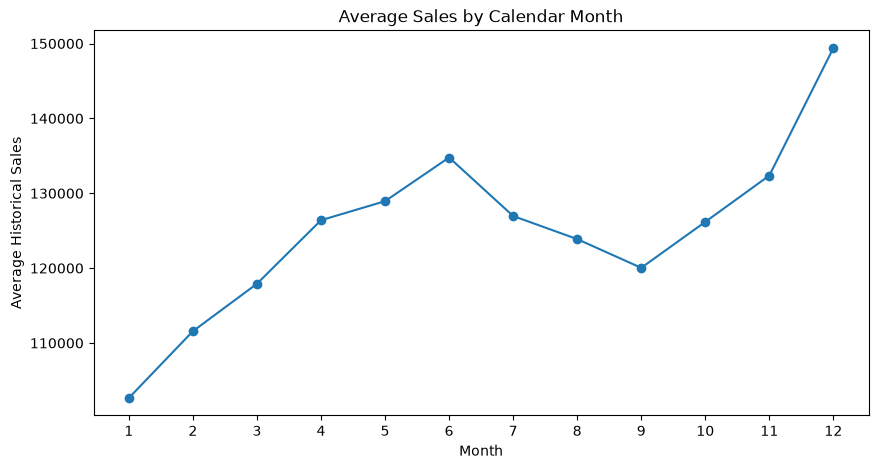

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(seasonal_summary.index, seasonal_summary.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average Historical Sales")
plt.title("Average Sales by Calendar Month")
plt.xticks(range(1, 13))
plt.show()

## 8. Forecasting Method 1 — Naive Forecast

The simplest possible forecast is:

> Tomorrow/month's forecast = most recent observed value.

This is a baseline. A useful forecast should beat a sensible baseline rather than being evaluated against nothing.

In [21]:
series = monthly_sales.set_index("date")["sales"]

train = series.iloc[:-6]
test = series.iloc[-6:]

naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

pd.DataFrame({
    "actual": test,
    "naive_forecast": naive_forecast
})

,actual,naive_forecast
date,,
2027-07-01,145361.391658,152192.042113
2027-08-01,137696.296508,152192.042113
2027-09-01,132543.977741,152192.042113
2027-10-01,142113.948751,152192.042113
2027-11-01,149319.315464,152192.042113
2027-12-01,166343.737037,152192.042113


## 9. Forecasting Method 2 — Moving Average

A moving average smooths recent observations.

Example:

```text
Forecast = average of the previous 3 periods
```

It is useful when the data has noise and recent observations are informative.

In [22]:
window = 3

moving_average_forecast = pd.Series(
    [train.iloc[-window:].mean()] * len(test),
    index=test.index
)

pd.DataFrame({
    "actual": test,
    "moving_average_forecast": moving_average_forecast
})

,actual,moving_average_forecast
date,,
2027-07-01,145361.391658,145711.1356
2027-08-01,137696.296508,145711.1356
2027-09-01,132543.977741,145711.1356
2027-10-01,142113.948751,145711.1356
2027-11-01,149319.315464,145711.1356
2027-12-01,166343.737037,145711.1356


## 10. Rolling Moving Average Across the Whole Series

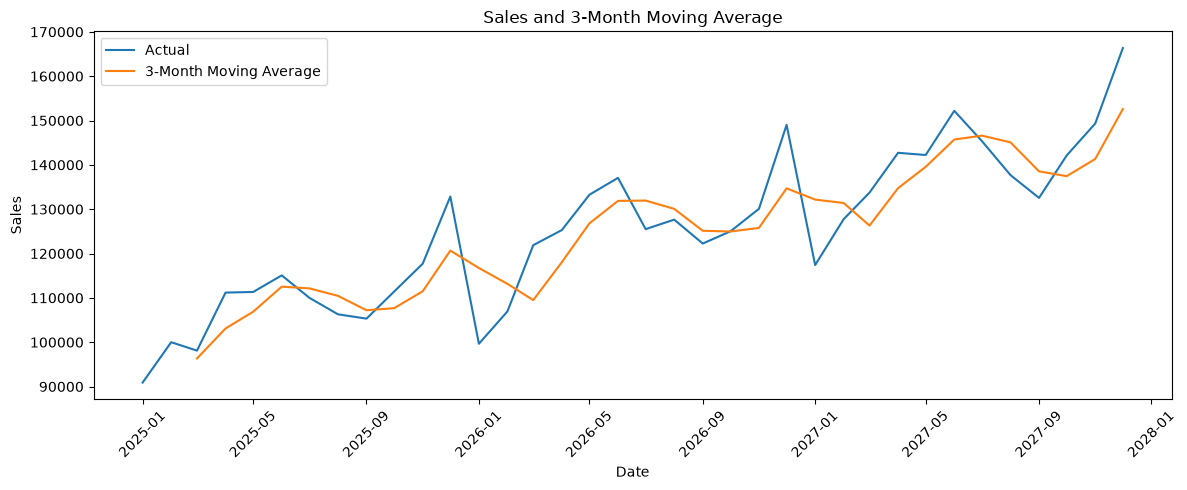

In [23]:
monthly_sales["rolling_3"] = monthly_sales["sales"].rolling(3).mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["date"], monthly_sales["sales"], label="Actual")
plt.plot(monthly_sales["date"], monthly_sales["rolling_3"], label="3-Month Moving Average")
plt.title("Sales and 3-Month Moving Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Forecasting Method 3 — Weighted Moving Average

A weighted moving average gives more importance to recent observations.

Example:

```text
Forecast =
0.50 × latest
+ 0.30 × previous
+ 0.20 × previous-2
```

This can respond faster to recent changes than a simple moving average.

In [24]:
weights = np.array([0.20, 0.30, 0.50])

recent = train.iloc[-3:].to_numpy()
weighted_forecast_value = np.sum(recent * weights)

weighted_forecast = pd.Series(weighted_forecast_value, index=test.index)
weighted_forecast

date
2027-07-01    147306.672556
2027-08-01    147306.672556
2027-09-01    147306.672556
2027-10-01    147306.672556
2027-11-01    147306.672556
2027-12-01    147306.672556
dtype: float64

## 12. Forecasting Method 4 — Simple Trend Projection

We can represent time as a numeric variable and fit a simple straight-line trend.

This is a **basic statistical trend model**, not a machine-learning lesson.

In [25]:
y = train.to_numpy()
x = np.arange(len(y))

slope, intercept = np.polyfit(x, y, 1)

future_x = np.arange(len(y), len(y) + len(test))
trend_forecast = pd.Series(
    slope * future_x + intercept,
    index=test.index
)

print("Slope:", slope)
print("Intercept:", intercept)

pd.DataFrame({
    "actual": test,
    "trend_forecast": trend_forecast
})

Slope: 1477.935899752449
Intercept: 99565.06309400669


,actual,trend_forecast
date,,
2027-07-01,145361.391658,143903.140087
2027-08-01,137696.296508,145381.075986
2027-09-01,132543.977741,146859.011886
2027-10-01,142113.948751,148336.947786
2027-11-01,149319.315464,149814.883686
2027-12-01,166343.737037,151292.819585


## 13. Compare Forecasts

We should not choose a forecast only because it “looks reasonable”.

Compare forecast errors.

### MAE — Mean Absolute Error

Average absolute error.

```text
MAE = average(|actual - forecast|)
```

Lower is better.

In [26]:
def mae(actual, forecast):
    return np.mean(np.abs(np.asarray(actual) - np.asarray(forecast)))

comparison = pd.DataFrame({
    "Naive": [mae(test, naive_forecast)],
    "Moving Average": [mae(test, moving_average_forecast)],
    "Weighted Moving Average": [mae(test, weighted_forecast)],
    "Trend": [mae(test, trend_forecast)]
})

comparison.T.rename(columns={0: "MAE"}).sort_values("MAE")

,MAE
Trend,7537.924984
Moving Average,8228.284841
Weighted Moving Average,8760.130493
Naive,11346.162561


## 14. Backtesting

A strong forecasting lesson should teach students not to judge a method from one arbitrary split.

Conceptually:

```text
Train → Forecast → Compare
Train → Forecast → Compare
Train → Forecast → Compare
```

This repeated evaluation is called **backtesting** in time-series work.

For this unit, students only need to understand the principle.

In [27]:
# Simple expanding-window backtest for a 1-step-ahead naive forecast
values = series.to_numpy()

errors = []

for i in range(6, len(values)):
    actual = values[i]
    forecast = values[i - 1]
    errors.append(abs(actual - forecast))

print("Average 1-step-ahead naive MAE:", np.mean(errors))

Average 1-step-ahead naive MAE: 9153.3746935911


## 15. Forecast Visualisation

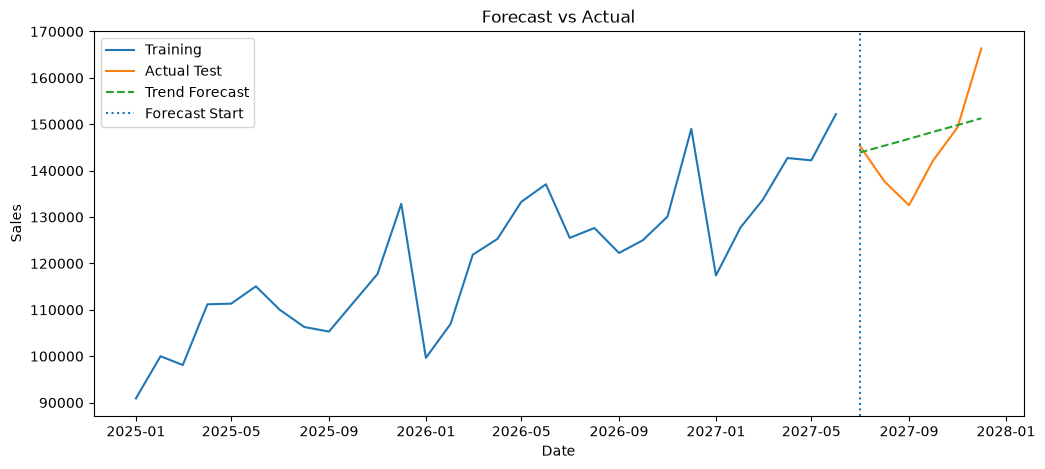

In [28]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label="Training")
plt.plot(test.index, test.values, label="Actual Test")
plt.plot(test.index, trend_forecast.values, label="Trend Forecast", linestyle="--")
plt.axvline(test.index[0], linestyle=":", label="Forecast Start")
plt.title("Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

## 16. From Forecast to Business Decision

A forecast is useful only when it influences action.

Examples:

### Inventory
Predicted demand ↑ → increase stock.

### Staffing
Expected traffic ↑ → schedule more employees.

### Finance
Expected revenue ↓ → review spending and pricing.

### Marketing
Expected seasonal demand ↑ → prepare campaign inventory earlier.

In [29]:
forecast_summary = pd.DataFrame({
    "month": test.index,
    "forecast_sales": trend_forecast.values
})

forecast_summary

,month,forecast_sales
0,2027-07-01,143903.140087
1,2027-08-01,145381.075986
2,2027-09-01,146859.011886
3,2027-10-01,148336.947786
4,2027-11-01,149814.883686
5,2027-12-01,151292.819585


## 17. Forecasting Limitations

Students should understand:

- unexpected events can break historical patterns
- seasonality can change
- data quality affects the forecast
- long-range forecasts are generally more uncertain
- forecasts depend on the method and assumptions
- a forecast should be monitored after deployment

Avoid presenting forecasts as certainty.

## 18. Guided Class Exercise

Use a new monthly dataset and require students to:

1. Plot the time series.
2. Explain the trend.
3. Identify likely seasonality.
4. Create a naive forecast.
5. Create a moving-average forecast.
6. Calculate MAE.
7. Compare methods.
8. Write a business recommendation.

In [30]:
# Student exercise starter

practice_dates = pd.date_range("2024-01-01", periods=30, freq="MS")
practice_sales = np.array([
    90, 95, 102, 98, 105, 112, 108, 104, 110, 118,
    125, 140, 100, 103, 109, 106, 114, 120, 116, 111,
    118, 126, 132, 145, 108, 112, 120, 116, 124, 132
], dtype=float)

practice = pd.DataFrame({
    "date": practice_dates,
    "sales": practice_sales
})

practice.head()

,date,sales
0,2024-01-01,90.0
1,2024-02-01,95.0
2,2024-03-01,102.0
3,2024-04-01,98.0
4,2024-05-01,105.0


## 19. Independent Task — “Should We Increase Inventory?”

Scenario:

A retailer wants to decide whether to increase inventory for the next quarter.

Students should provide:

- evidence of the historical trend
- evidence of seasonality if present
- one simple forecast
- forecast accuracy measure
- business recommendation
- one limitation or risk

## 20. Summary

Students should now understand:

- the difference between descriptive, diagnostic, predictive and prescriptive analytics
- basic time-series concepts
- naive forecasting
- moving-average forecasting
- simple trend projection
- forecast errors
- backtesting as a concept
- the difference between a forecast and a business recommendation

**Machine learning is deliberately not implemented here; it belongs to the next unit.**